# 02 · Preprocessing + RUL
**Owner:** Wijayagurusinghe · **Branch:** `data/02-preprocessing-rul`

Keep only cells that actually reach end-of-life, add the RUL label (`RUL = cycle_life − cycle`), do safe cleaning, and save `preprocessed.parquet`.


In [11]:
# --- Colab setup (run first) ---
import os
REPO = '/content/ev-battery-rul-prediction'   # absolute path -> safe to re-run
if not os.path.exists(REPO):
    !git clone https://github.com/Chathumi-Senanayake/ev-battery-rul-prediction.git {REPO}
%cd {REPO}
!git pull -q
!pip install -q -r requirements.txt
import sys
if REPO not in sys.path: sys.path.insert(0, REPO)

# Try Google Drive (data persists across sessions). If auth fails, fall back
# to local Colab storage so you are never blocked.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/ev_battery_data'
except Exception as e:
    print('Drive mount failed -> using local storage:', e)
    DATA_DIR = '/content/ev_battery_data'
os.makedirs(DATA_DIR, exist_ok=True)
print('DATA_DIR =', DATA_DIR)


/content/ev-battery-rul-prediction
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR = /content/drive/MyDrive/ev_battery_data


In [12]:
import pickle, pandas as pd
from src.preprocessing import (build_summary_table, add_rul, reached_eol,
    basic_clean, quality_report, print_report, EOL_AH)
bat_dict = pickle.load(open(os.path.join(DATA_DIR,'bat_dict.pkl'),'rb'))


### Drop cells that never reach EOL (≤ 0.88 Ah)


In [13]:
eol = reached_eol(bat_dict)
bad = [c for c,ok in eol.items() if not ok]
print('cells not reaching EOL:', bad or 'none')
bat_dict = {c:d for c,d in bat_dict.items() if eol[c]}
print('cells kept:', len(bat_dict))


cells not reaching EOL: none
cells kept: 124


### Build table + RUL label + clean


In [14]:
df = add_rul(build_summary_table(bat_dict))
clean = basic_clean(df, drop_first_cycle=True)
print('rows:', len(df), '->', len(clean), '| cells:', clean['cell'].nunique())
clean.to_parquet(os.path.join(DATA_DIR,'preprocessed.parquet'), index=False)
print_report(quality_report(clean))


rows: 100501 -> 100377 | cells: 124
rows: 100377   cells: 124
duplicate (cell,cycle): 0
bad cycle order cells : none
IR<=0: 21   QD<=0: 0
out of range: {'QD': 4, 'QC': 29, 'IR': 0, 'Tavg': 0, 'Tmin': 0, 'Tmax': 0, 'chargetime': 14}
missing (non-zero): none


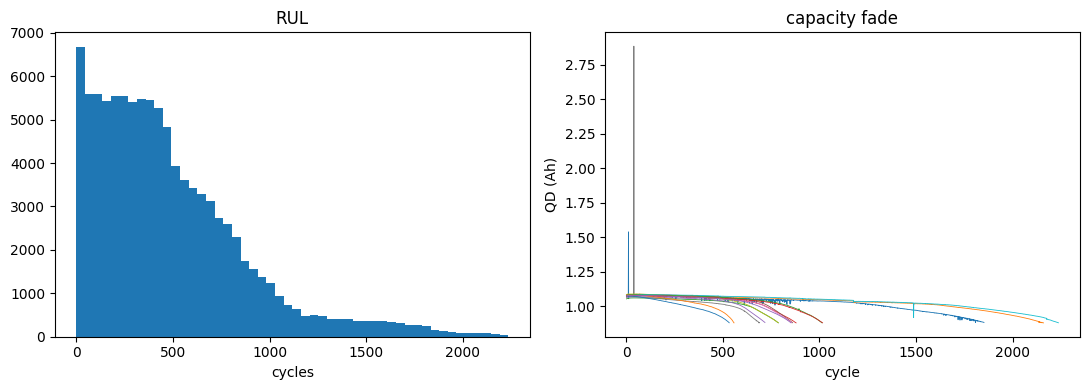

In [15]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(clean['RUL'],bins=50); ax[0].set_title('RUL'); ax[0].set_xlabel('cycles')
for c in list(clean['cell'].unique())[:15]:
    g=clean[clean['cell']==c]; ax[1].plot(g['cycle'],g['QD'],lw=.6)
ax[1].set_title('capacity fade'); ax[1].set_xlabel('cycle'); ax[1].set_ylabel('QD (Ah)')
plt.tight_layout(); plt.show()


In [17]:
import numpy as np
for b in ['b1','b2','b3']:
    cells = {c:d for c,d in bat_dict.items() if c.startswith(b)}
    mins  = [np.nanmin(d['summary']['QD']) for d in cells.values()]
    lives = [float(np.ravel(d['cycle_life'])[0]) for d in cells.values()]
    print(f"{b}: {len(cells)} cells | min-QD {min(mins):.3f}-{max(mins):.3f} | cycle_life {min(lives):.0f}-{max(lives):.0f}")

b1: 41 cells | min-QD 0.000-0.000 | cycle_life 534-2237
b2: 43 cells | min-QD 0.825-0.828 | cycle_life 148-713
b3: 40 cells | min-QD 0.880-0.882 | cycle_life 541-1935


In [19]:
import numpy as np, pandas as pd
cs = clean.sort_values(['cell','cycle']).copy()

# 1. IR <= 0 anomalies — මොන cells/cycles ද?
ir0 = cs[cs['IR'] <= 0]
print('IR<=0:', len(ir0), '| cells:', ir0.groupby('cell').size().to_dict())

# 2. out-of-range rows
for col,(lo,hi) in {'QD':(0,1.3),'QC':(0,1.3),'chargetime':(0,60)}.items():
    oor = cs[(cs[col]<lo)|(cs[col]>hi)]
    print(f'{col} OOR: {len(oor)} | cells:', list(oor["cell"].unique())[:8])

# 3. sudden capacity jumps (spikes/dropouts) trajectory මැද
cs['qd_jump'] = cs.groupby('cell')['QD'].diff().abs()
spk = cs[cs['qd_jump'] > 0.05]
print('capacity spikes (>0.05 Ah):', len(spk))
print(spk.groupby('cell').size().sort_values(ascending=False).head(8).to_dict())

# 4. QD > nominal (1.1) — impossible capacity
print('QD>1.1:', (cs['QD']>1.1).sum(), '| QC>1.1:', (cs['QC']>1.1).sum())

IR<=0: 21 | cells: {'b1c0': 2, 'b1c1': 3, 'b1c11': 1, 'b1c16': 1, 'b1c2': 3, 'b1c20': 1, 'b1c21': 1, 'b1c23': 1, 'b1c3': 1, 'b1c4': 2, 'b1c40': 1, 'b1c5': 1, 'b1c6': 1, 'b1c7': 1, 'b1c9': 1}
QD OOR: 4 | cells: ['b1c0', 'b1c18', 'b2c12', 'b2c44']
QC OOR: 29 | cells: ['b1c0', 'b1c18', 'b2c12', 'b2c44']
chargetime OOR: 14 | cells: ['b1c14', 'b1c15', 'b1c2', 'b1c24', 'b1c3', 'b1c41', 'b1c5', 'b2c12']
capacity spikes (>0.05 Ah): 30
{'b1c0': 2, 'b1c18': 2, 'b1c2': 2, 'b1c5': 2, 'b2c10': 2, 'b2c11': 2, 'b2c12': 2, 'b2c20': 2}
QD>1.1: 4 | QC>1.1: 37


In [20]:
import numpy as np
cs = clean.sort_values(['cell','cycle']).copy()

# A) impossible capacity -> remove
bad = (cs['QD'] > 1.2) | (cs['QC'] > 1.2)
print('impossible-capacity rows removed:', int(bad.sum()))
cs = cs[~bad].copy()

# B) IR <= 0 -> NaN then forward/back-fill within each cell
cs['IR'] = cs['IR'].where(cs['IR'] > 0)
cs['IR'] = cs.groupby('cell')['IR'].ffill().bfill()

print('rows:', len(clean), '->', len(cs), '| cells:', cs['cell'].nunique())
print('check -> QD>1.2:', int((cs['QD']>1.2).sum()),
      '| QC>1.2:', int((cs['QC']>1.2).sum()),
      '| IR<=0:', int((cs['IR']<=0).sum()))

impossible-capacity rows removed: 32
rows: 100377 -> 100345 | cells: 124
check -> QD>1.2: 0 | QC>1.2: 0 | IR<=0: 0


In [21]:
import numpy as np, pandas as pd

# 1. curve quality per cell (invalid Qdlin/Tdlin curves)
def bad_curves(d):
    n=0
    for j in range(len(d['cycles'])):
        c=d['cycles'][str(j)]; q=np.asarray(c['Qdlin'],float); t=np.asarray(c['Tdlin'],float)
        if not(np.all(np.isfinite(q))and np.all(np.isfinite(t))and q.min()>-0.1 and q.max()<1.3 and t.min()>20 and t.max()<60): n+=1
    return n
bc={c:bad_curves(d) for c,d in bat_dict.items()}
print('cells with invalid curves:', {c:n for c,n in bc.items() if n>0})

# 2. RUL sanity: min/max RUL per cell + is it monotonic?
g=clean.sort_values(['cell','cycle']).groupby('cell')
mono=(g['RUL'].apply(lambda s: (s.diff().dropna()<=0).all()))
print('non-monotonic RUL cells:', list(mono[~mono].index))
print('RUL min across cells (should be ~0-1):', clean.groupby('cell')['RUL'].min().max())

# 3. batch lifetime distribution
print(clean.groupby('batch')['cycle_life'].agg(['min','median','max','nunique']))

# 4. RUL skew
print('RUL quantiles:', clean['RUL'].quantile([.1,.25,.5,.75,.9]).round(0).to_dict())

# 5. cells shorter than 100 usable cycles?
sizes=clean.groupby('cell').size()
print('cells with <100 rows:', sizes[sizes<100].to_dict())

cells with invalid curves: {'b1c0': 2, 'b1c1': 2, 'b1c2': 2, 'b1c3': 4, 'b1c4': 2, 'b1c5': 2, 'b1c6': 1, 'b1c7': 1, 'b1c9': 1, 'b1c11': 1, 'b1c14': 1, 'b1c15': 1, 'b1c16': 2, 'b1c17': 1, 'b1c18': 1, 'b1c19': 1, 'b1c20': 2, 'b1c21': 3, 'b1c23': 2, 'b1c24': 2, 'b1c25': 1, 'b1c26': 2, 'b1c27': 1, 'b1c28': 1, 'b1c29': 1, 'b1c30': 1, 'b1c31': 1, 'b1c32': 1, 'b1c33': 1, 'b1c34': 2, 'b1c35': 1, 'b1c36': 3, 'b1c37': 2, 'b1c38': 1, 'b1c39': 1, 'b1c40': 3, 'b1c41': 1, 'b1c42': 2, 'b1c43': 1, 'b1c44': 1, 'b1c45': 1, 'b2c4': 1, 'b2c6': 1, 'b2c10': 1, 'b2c11': 1, 'b2c12': 1, 'b2c13': 1, 'b2c20': 1, 'b2c22': 1, 'b2c26': 1, 'b2c28': 1, 'b2c37': 1, 'b2c40': 5, 'b2c42': 1, 'b2c44': 1}
non-monotonic RUL cells: []
RUL min across cells (should be ~0-1): 1.0
         min  median     max  nunique
batch                                
b1     534.0   870.0  2237.0       39
b2     148.0   485.0   713.0       39
b3     541.0  1039.0  1935.0       38
RUL quantiles: {0.1: 72.0, 0.25: 193.0, 0.5: 399.0, 0.75: 674.

In [22]:
print('cells per batch:', clean.groupby('batch')['cell'].nunique().to_dict())


cells per batch: {'b1': 41, 'b2': 43, 'b3': 40}
